# Autoregressive Text Generation with Simple RNN, Bidirectional RNN, LSTM and GRU

**Dataset:** Human Conversation Training Data (`human_chat.txt`) — two-person casual chat, Kaggle:
<https://www.kaggle.com/datasets/projjal1/human-conversation-training-data>


## 1. Setup & configuration

In [1]:
import os, re, time, math, json, random, collections
from pathlib import Path
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 200, "display.max_columns", 50)
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)

# ---- locate repository root (works whether the notebook is started from repo root or from notebooks/) ----
ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
DATA_PATH = ROOT / "data" / "human_chat.txt"
RESULTS   = ROOT / "results";  RESULTS.mkdir(exist_ok=True)
MODELS    = ROOT / "models";   MODELS.mkdir(exist_ok=True)
print("Repo root:", ROOT)

I0000 00:00:1791946549.257303     440 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1791946551.109235     440 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0 | Keras 3.15.1
Repo root: /home/claude/repo


In [ ]:
# ======================= EXPERIMENT CONFIGURATION (identical for all four models) =======================
CFG = dict(
    # data
    seq_len=12,            
    min_freq=2,            
    train_frac=0.80, val_frac=0.10,       
    emb_dim=128, units=256, dropout=0.3,
    batch_size=128, max_epochs=40, patience=3, lr=1e-3, clipnorm=1.0,
    train_seeds=[42, 43, 44], gen_seed=42,   
    gen_len=40, temperatures=[0.3, 0.7, 1.0, 1.5], n_samples_per_seed=20,
)
if os.environ.get("QUICK_RUN") == "1":     
    CFG.update(max_epochs=1, train_seeds=[42], n_samples_per_seed=3)
    print(">>> QUICK_RUN mode: results are NOT meaningful <<<")

KINDS = ["SimpleRNN", "BiRNN", "LSTM", "GRU"]
PRETTY = {"SimpleRNN": "Simple RNN", "BiRNN": "Bidirectional RNN", "LSTM": "LSTM", "GRU": "GRU"}
COLORS = {"SimpleRNN": "#d62728", "BiRNN": "#ff7f0e", "LSTM": "#1f77b4", "GRU": "#2ca02c"}
print(json.dumps(CFG, indent=1))

{
 "seq_len": 12,
 "min_freq": 2,
 "train_frac": 0.8,
 "val_frac": 0.1,
 "emb_dim": 128,
 "units": 256,
 "dropout": 0.3,
 "batch_size": 128,
 "max_epochs": 40,
 "patience": 3,
 "lr": 0.001,
 "clipnorm": 1.0,
 "train_seeds": [
  42,
  43,
  44
 ],
 "gen_seed": 42,
 "gen_len": 40,
 "temperatures": [
  0.3,
  0.7,
  1.0,
  1.5
 ],
 "n_samples_per_seed": 20
}


## 2. Dataset description


In [3]:
raw = DATA_PATH.read_text(encoding="utf-8")
lines = [l.strip() for l in raw.split("\n") if l.strip()]
assert all(l.startswith(("Human 1:", "Human 2:")) for l in lines), "unexpected line format"
speaker = [l.split(":", 1)[0] for l in lines]
body    = [l.split(":", 1)[1].strip() for l in lines]
turn_len = np.array([len(b.split()) for b in body])
non_ascii = collections.Counter(ch for ch in raw if ord(ch) > 127)

print(f"File size              : {len(raw.encode('utf-8'))/1024:.1f} KB")
print(f"Dialogue turns (lines) : {len(lines)}   (Human 1: {speaker.count('Human 1')}, Human 2: {speaker.count('Human 2')})")
print(f"Words per turn         : mean {turn_len.mean():.1f} | median {np.median(turn_len):.0f} | min {turn_len.min()} | max {turn_len.max()}")
print(f"Non-ASCII characters   : {sum(non_ascii.values())} (mostly emojis) -> top: {non_ascii.most_common(6)}")
print("\nFirst 8 lines of the file:")
for l in lines[:8]:
    print("  ", l[:110] + ("..." if len(l) > 110 else ""))

File size              : 113.4 KB
Dialogue turns (lines) : 1494   (Human 1: 764, Human 2: 730)
Words per turn         : mean 13.1 | median 11 | min 1 | max 151
Non-ASCII characters   : 133 (mostly emojis) -> top: [('🙂', 85), ('’', 14), ('😉', 8), ('😞', 5), ('😛', 4), ('😂', 4)]

First 8 lines of the file:
   Human 1: Hi!
   Human 2: What is your favorite holiday?
   Human 1: one where I get to meet lots of different people.
   Human 2: What was the most number of people you have ever met during a holiday?
   Human 1: Hard to keep a count. Maybe 25.
   Human 2: Which holiday was that?
   Human 1: I think it was Australia
   Human 2: Do you still talk to the people you met?


## 3. Pre-processing and input–target sequence construction 


In [4]:
REPL = {"\u2019": "'", "\u2018": "'", "\u201c": '"', "\u201d": '"', "\u2026": "."}
TAGS = {"<h1>", "<h2>"}
TOKEN_RE = re.compile(r"<h[12]>|[a-z0-9]+(?:'[a-z]+)?|[.,!?]")

def clean(text):
    for k, v in REPL.items():
        text = text.replace(k, v)
    text = text.encode("ascii", "ignore").decode()                  # drop emojis / other non-ASCII
    text = text.replace("Human 1:", " <h1> ").replace("Human 2:", " <h2> ")
    text = re.sub(r"([.!?,])\1+", r"\1", text)                       # collapse '!!!' '...' '??'
    return text.lower()

def tokenize(text):
    return TOKEN_RE.findall(clean(text))

tokens = tokenize(raw)
print("Raw example   :", lines[9][:150])
print("Token example :", tokenize(lines[9])[:30])
print(f"\nTotal tokens: {len(tokens):,} | unique tokens: {len(set(tokens)):,} "
      f"| type/token ratio: {len(set(tokens))/len(tokens):.3f}")

Raw example   : Human 2: Yea, me too. I feel like God often puts strangers in front of you, and gives you an opportunity to connect with them in that moment in deeply
Token example : ['<h2>', 'yea', ',', 'me', 'too', '.', 'i', 'feel', 'like', 'god', 'often', 'puts', 'strangers', 'in', 'front', 'of', 'you', ',', 'and', 'gives', 'you', 'an', 'opportunity', 'to', 'connect', 'with', 'them', 'in', 'that', 'moment']

Total tokens: 24,031 | unique tokens: 2,789 | type/token ratio: 0.116


In [ ]:
# ---------- chronological split of the token stream ----------
n = len(tokens)
n_tr, n_va = int(CFG["train_frac"] * n), int((CFG["train_frac"] + CFG["val_frac"]) * n)
train_tok, val_tok, test_tok = tokens[:n_tr], tokens[n_tr:n_va], tokens[n_va:]

# ---------- vocabulary from the TRAIN split only ----------
train_counts = collections.Counter(train_tok)
vocab = ["<pad>", "<unk>"] + [w for w, c in train_counts.most_common() if c >= CFG["min_freq"]]
w2i = {w: i for i, w in enumerate(vocab)}
V = len(vocab)
PAD, UNK = w2i["<pad>"], w2i["<unk>"]
encode = lambda toks: np.array([w2i.get(t, UNK) for t in toks], dtype=np.int32)
decode = lambda ids: [vocab[i] for i in ids]

train_ids, val_ids, test_ids = encode(train_tok), encode(val_tok), encode(test_tok)

def make_windows(ids, L):
    n_win = len(ids) - L
    X = np.ascontiguousarray(np.lib.stride_tricks.sliding_window_view(ids, L)[:n_win])
    y = ids[L:].copy()
    return X, y

L = CFG["seq_len"]
Xtr, ytr = make_windows(train_ids, L)
Xva, yva = make_windows(val_ids, L)
Xte, yte = make_windows(test_ids, L)

split_df = pd.DataFrame({
    "tokens": [len(train_ids), len(val_ids), len(test_ids)],
    "sequences": [len(Xtr), len(Xva), len(Xte)],
    "<unk> rate (%)": [100 * (a == UNK).mean() for a in (train_ids, val_ids, test_ids)],
}, index=["train", "validation", "test"]).round(2)
print(f"Vocabulary size (incl. <pad>, <unk>): {V}  | train tokens covered: {100*(train_ids!=UNK).mean():.1f}%")
display(split_df)

print("\nOne input -> target pair (decoded):")
print("  X :", " ".join(decode(Xtr[100])))
print("  y :", vocab[ytr[100]])
print("  X shape:", Xtr.shape, "| y shape:", ytr.shape)

Vocabulary size (incl. <pad>, <unk>): 1144  | train tokens covered: 93.4%


,tokens,sequences,<unk> rate (%)
train,19224,19212,6.61
validation,2403,2391,13.03
test,2404,2392,13.39



One input -> target pair (decoded):
  X : too . i feel like god often <unk> strangers in <unk> of
  y : you
  X shape: (19212, 12) | y shape: (19212,)


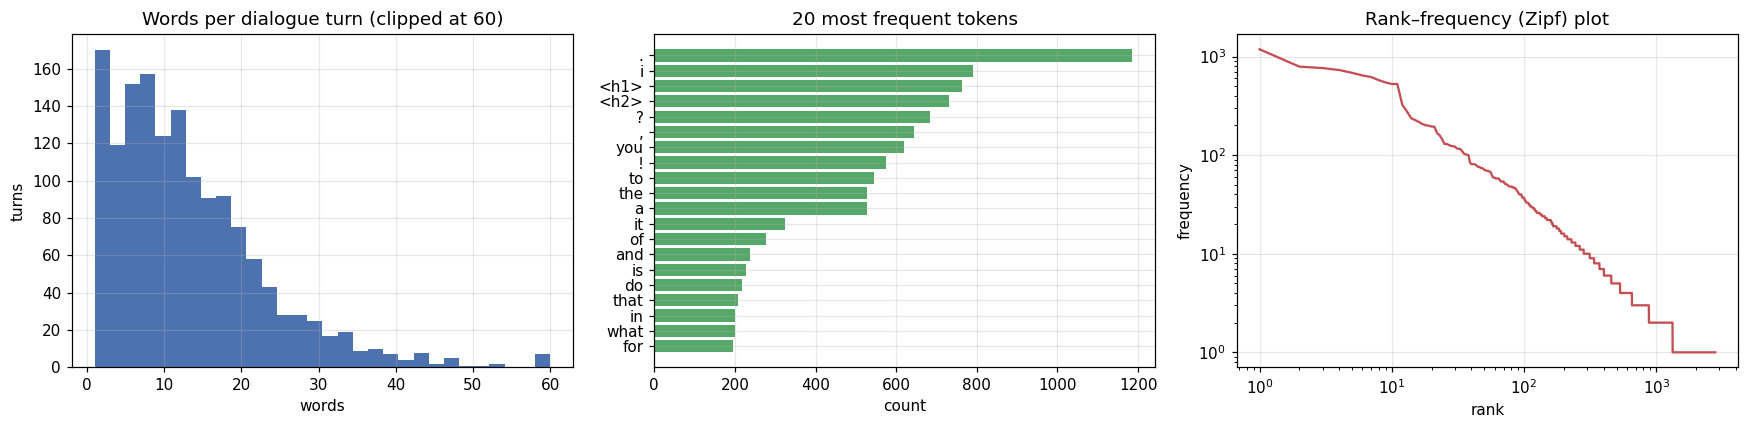

In [6]:
# ---------- dataset overview figure ----------
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].hist(np.clip(turn_len, 0, 60), bins=30, color="#4c72b0")
ax[0].set(title="Words per dialogue turn (clipped at 60)", xlabel="words", ylabel="turns")
top = collections.Counter(tokens).most_common(20)
ax[1].barh([w for w, _ in top][::-1], [c for _, c in top][::-1], color="#55a868")
ax[1].set(title="20 most frequent tokens", xlabel="count")
freqs = np.array(sorted(collections.Counter(tokens).values(), reverse=True))
ax[2].loglog(np.arange(1, len(freqs) + 1), freqs, color="#c44e52")
ax[2].set(title="Rank–frequency (Zipf) plot", xlabel="rank", ylabel="frequency")
plt.tight_layout(); plt.savefig(RESULTS / "fig_dataset_overview.png", bbox_inches="tight"); plt.show()

## 4. Model definitions


`Embedding(V, 128)  →  [ recurrent layer ]  →  Dropout(0.3)  →  Dense(V)  (logits)`

| Model | Recurrent layer |
|---|---|
| Simple RNN | `SimpleRNN(256)` |
| Bidirectional RNN | `Bidirectional(SimpleRNN(256))` |
| LSTM | `LSTM(256)` |
| GRU | `GRU(256)` |


In [ ]:
def build_model(kind, vocab_size, seed):
    keras.utils.set_random_seed(seed)
    rnn = {
        "SimpleRNN": lambda: layers.SimpleRNN(CFG["units"]),
        "BiRNN":     lambda: layers.Bidirectional(layers.SimpleRNN(CFG["units"])),
        "LSTM":      lambda: layers.LSTM(CFG["units"]),
        "GRU":       lambda: layers.GRU(CFG["units"]),
    }[kind]()
    model = keras.Sequential([
        layers.Input(shape=(CFG["seq_len"],)),
        layers.Embedding(vocab_size, CFG["emb_dim"]),
        rnn,
        layers.Dropout(CFG["dropout"]),
        layers.Dense(vocab_size),                               
    ], name=kind)
    model.compile(
        optimizer=keras.optimizers.Adam(CFG["lr"], clipnorm=CFG["clipnorm"]),
        loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
        metrics=[keras.metrics.SparseCategoricalAccuracy(name="acc"),
                 keras.metrics.SparseTopKCategoricalAccuracy(k=5, name="top5")],
    )
    return model

param_table = pd.DataFrame({PRETTY[k]: [build_model(k, V, 0).count_params()] for k in KINDS},
                           index=["trainable parameters"]).T
display(param_table)
build_model("LSTM", V, 0).summary()

,trainable parameters
Simple RNN,539000
Bidirectional RNN,930424
LSTM,834680
GRU,736888


Model: "LSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_4 (Embedding)         │ (None, 12, 128)        │       146,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 256)            │       394,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1144)           │       294,008 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 834,680 (3.18 MB)

 Trainable params: 834,680 (3.18 MB)

 Non-trainable params: 0 (0.00 B)

## 5. Training all four models 


In [8]:
class EpochTimer(keras.callbacks.Callback):
    def on_train_begin(self, logs=None): self.times = []
    def on_epoch_begin(self, epoch, logs=None): self._t = time.perf_counter()
    def on_epoch_end(self, epoch, logs=None): self.times.append(time.perf_counter() - self._t)

def train_one(kind, seed):
    model = build_model(kind, V, seed)
    timer = EpochTimer()
    stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=CFG["patience"], restore_best_weights=True)
    t0 = time.perf_counter()
    hist = model.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=CFG["max_epochs"], batch_size=CFG["batch_size"],
                     callbacks=[stop, timer], shuffle=True, verbose=0)
    total = time.perf_counter() - t0
    h = hist.history
    best = int(np.argmin(h["val_loss"]))
    ev = lambda X, y: model.evaluate(X, y, batch_size=512, verbose=0, return_dict=True)   # eval mode (no dropout)
    tr, va, te = ev(Xtr, ytr), ev(Xva, yva), ev(Xte, yte)
    row = dict(model=kind, seed=seed, params=model.count_params(), epochs_run=len(h["loss"]), best_epoch=best + 1,
               train_time_s=total, sec_per_epoch=float(np.mean(timer.times)), time_to_best_s=float(sum(timer.times[:best + 1])),
               train_loss=tr["loss"], val_loss=va["loss"], test_loss=te["loss"],
               train_ppl=math.exp(tr["loss"]), val_ppl=math.exp(va["loss"]), test_ppl=math.exp(te["loss"]),
               train_acc=tr["acc"], val_acc=va["acc"], test_acc=te["acc"], test_top5=te["top5"])
    hdf = pd.DataFrame({"epoch": np.arange(1, len(h["loss"]) + 1), "loss": h["loss"], "val_loss": h["val_loss"],
                        "acc": h["acc"], "val_acc": h["val_acc"], "epoch_time_s": timer.times})
    hdf.insert(0, "seed", seed); hdf.insert(0, "model", kind)
    return model, row, hdf

rows, hists, gen_models = [], [], {}
for seed in CFG["train_seeds"]:
    for kind in KINDS:
        model, row, hdf = train_one(kind, seed)
        rows.append(row); hists.append(hdf)
        print(f"[seed {seed}] {PRETTY[kind]:<18} epochs={row['epochs_run']:>2} (best {row['best_epoch']:>2}) "
              f"time={row['train_time_s']:6.1f}s | val_ppl={row['val_ppl']:7.1f} | test_ppl={row['test_ppl']:7.1f} "
              f"| test_acc={100*row['test_acc']:.2f}%")
        if seed == CFG["gen_seed"]:
            gen_models[kind] = model
            model.save(MODELS / f"{kind}.keras", include_optimizer=False)
        else:
            keras.backend.clear_session()

runs_df = pd.DataFrame(rows)
hist_df = pd.concat(hists, ignore_index=True)
runs_df.to_csv(RESULTS / "results_all_runs.csv", index=False)
hist_df.to_csv(RESULTS / "training_history.csv", index=False)

[seed 42] Simple RNN         epochs= 9 (best  6) time=  47.5s | val_ppl=   66.3 | test_ppl=   64.9 | test_acc=22.07%


[seed 42] Bidirectional RNN  epochs= 7 (best  4) time=  42.9s | val_ppl=   80.2 | test_ppl=   76.4 | test_acc=18.69%


[seed 42] LSTM               epochs=15 (best 12) time= 154.9s | val_ppl=   61.0 | test_ppl=   59.2 | test_acc=24.00%


[seed 42] GRU                epochs=10 (best  7) time= 103.9s | val_ppl=   59.2 | test_ppl=   58.7 | test_acc=23.37%


[seed 43] Simple RNN         epochs= 9 (best  6) time=  47.5s | val_ppl=   68.7 | test_ppl=   64.5 | test_acc=22.91%


...

[seed 43] GRU                epochs= 9 (best  6) time=  93.9s | val_ppl=   60.7 | test_ppl=   56.7 | test_acc=23.87%


[seed 44] Simple RNN         epochs= 9 (best  6) time=  47.2s | val_ppl=   66.2 | test_ppl=   64.0 | test_acc=22.28%


[seed 44] Bidirectional RNN  epochs= 6 (best  3) time=  43.1s | val_ppl=   73.5 | test_ppl=   70.5 | test_acc=20.53%


[seed 44] LSTM               epochs=15 (best 12) time= 150.7s | val_ppl=   60.8 | test_ppl=   59.4 | test_acc=23.62%


[seed 44] GRU                epochs= 9 (best  6) time=  93.8s | val_ppl=   58.9 | test_ppl=   57.7 | test_acc=24.08%


## 6. Quantitative evaluation & comparison 


In [9]:
class TrigramLM:
    # interpolated trigram / bigram / add-one-unigram language model over token ids
    def __init__(self, ids, V, lambdas=(0.6, 0.3, 0.1)):
        ids = list(map(int, ids))
        self.V, self.N, self.lam = V, len(ids), lambdas
        self.c1 = collections.Counter(ids)
        self.c2 = collections.Counter(zip(ids, ids[1:]))
        self.c3 = collections.Counter(zip(ids, ids[1:], ids[2:]))
    def p_uni(self, w): return (self.c1[w] + 1) / (self.N + self.V)
    def prob(self, u, v, w):
        p1 = self.p_uni(w)
        p2 = self.c2[(v, w)] / self.c1[v] if self.c1[v] else None
        cuv = self.c2[(u, v)]
        p3 = self.c3[(u, v, w)] / cuv if cuv else None
        parts = [(self.lam[0], p3), (self.lam[1], p2), (self.lam[2], p1)]
        tot = sum(a for a, p in parts if p is not None)
        return sum(a * p for a, p in parts if p is not None) / tot
    def perplexity(self, ids, start):
        # perplexity of ids[start:], each predicted from the two previous tokens
        lp = [math.log(self.prob(ids[i - 2], ids[i - 1], ids[i])) for i in range(start, len(ids))]
        return math.exp(-np.mean(lp))

lm = TrigramLM(train_ids, V)
uni_ppl = math.exp(-np.mean([math.log(lm.p_uni(int(w))) for w in yte]))
tri_ppl = lm.perplexity(list(map(int, test_ids)), start=L)     # same target positions as the neural models
print(f"Unigram baseline test perplexity : {uni_ppl:7.1f}")
print(f"Trigram baseline test perplexity : {tri_ppl:7.1f}")

Unigram baseline test perplexity :   148.2
Trigram baseline test perplexity :    83.4


In [10]:
metrics = ["params", "epochs_run", "best_epoch", "train_time_s", "sec_per_epoch", "time_to_best_s",
           "train_loss", "val_loss", "test_loss", "train_ppl", "val_ppl", "test_ppl", "train_acc", "val_acc", "test_acc", "test_top5"]
agg = runs_df.groupby("model")[metrics].agg(["mean", "std"]).reindex(KINDS)
agg.to_csv(RESULTS / "results_summary_mean_std.csv")

def ms(col, fmt="{:.2f}", scale=1.0):
    return [f"{fmt.format(scale*agg[(col,'mean')][k])} ± {fmt.format(scale*agg[(col,'std')][k])}" for k in KINDS]

summary = pd.DataFrame({
    "Params": [f"{int(agg[('params','mean')][k]):,}" for k in KINDS],
    "Epochs run": ms("epochs_run", "{:.1f}"),
    "Train time (s)": ms("train_time_s", "{:.0f}"),
    "Sec/epoch": ms("sec_per_epoch", "{:.1f}"),
    "Test loss": ms("test_loss", "{:.3f}"),
    "Test perplexity": ms("test_ppl", "{:.1f}"),
    "Top-1 acc (%)": ms("test_acc", "{:.2f}", 100),
    "Top-5 acc (%)": ms("test_top5", "{:.2f}", 100),
    "Train ppl": ms("train_ppl", "{:.1f}"),
}, index=[PRETTY[k] for k in KINDS])
summary.to_csv(RESULTS / "results_summary_table.csv")
print("Mean ± std over seeds", CFG["train_seeds"], f"(n-gram baselines: unigram ppl {uni_ppl:.1f}, trigram ppl {tri_ppl:.1f})")
display(summary)
print("\nPer-seed results:")
display(runs_df[["model", "seed", "epochs_run", "best_epoch", "train_time_s", "test_loss", "test_ppl", "test_acc", "test_top5"]]
        .round({"train_time_s": 1, "test_loss": 3, "test_ppl": 1, "test_acc": 4, "test_top5": 4}))

Mean ± std over seeds [42, 43, 44] (n-gram baselines: unigram ppl 148.2, trigram ppl 83.4)


,Params,Epochs run,Train time (s),Sec/epoch,Test loss,Test perplexity,Top-1 acc (%),Top-5 acc (%),Train ppl
Simple RNN,"539,000",9.0 ± 0.0,47 ± 0,5.0 ± 0.0,4.166 ± 0.007,64.4 ± 0.5,22.42 ± 0.44,45.96 ± 0.31,41.5 ± 0.5
Bidirectional RNN,"930,424",6.3 ± 0.6,46 ± 6,6.8 ± 1.0,4.328 ± 0.069,75.9 ± 5.2,19.36 ± 1.02,42.53 ± 1.72,58.2 ± 7.1
LSTM,"834,680",15.0 ± 0.0,153 ± 2,10.1 ± 0.2,4.089 ± 0.011,59.7 ± 0.6,23.75 ± 0.22,47.06 ± 0.15,37.2 ± 0.7
GRU,"736,888",9.3 ± 0.6,97 ± 6,10.1 ± 0.0,4.055 ± 0.017,57.7 ± 1.0,23.77 ± 0.37,46.73 ± 0.39,37.0 ± 3.2



Per-seed results:


,model,seed,epochs_run,best_epoch,train_time_s,test_loss,test_ppl,test_acc,test_top5
0,SimpleRNN,42,9,6,47.5,4.173,64.9,0.2207,0.4565
1,BiRNN,42,7,4,42.9,4.336,76.4,0.1869,0.4360
2,LSTM,42,15,12,154.9,4.081,59.2,0.2400,0.4707
3,GRU,42,10,7,103.9,4.072,58.7,0.2337,0.4628
4,SimpleRNN,43,9,6,47.5,4.166,64.5,0.2291,0.4628
5,BiRNN,43,6,3,53.2,4.393,80.9,0.1885,0.4055
6,LSTM,43,15,12,154.9,4.101,60.4,0.2362,0.4720
7,GRU,43,9,6,93.9,4.038,56.7,0.2387,0.4699
8,SimpleRNN,44,9,6,47.2,4.159,64.0,0.2228,0.4594
9,BiRNN,44,6,3,43.1,4.255,70.5,0.2053,0.4344


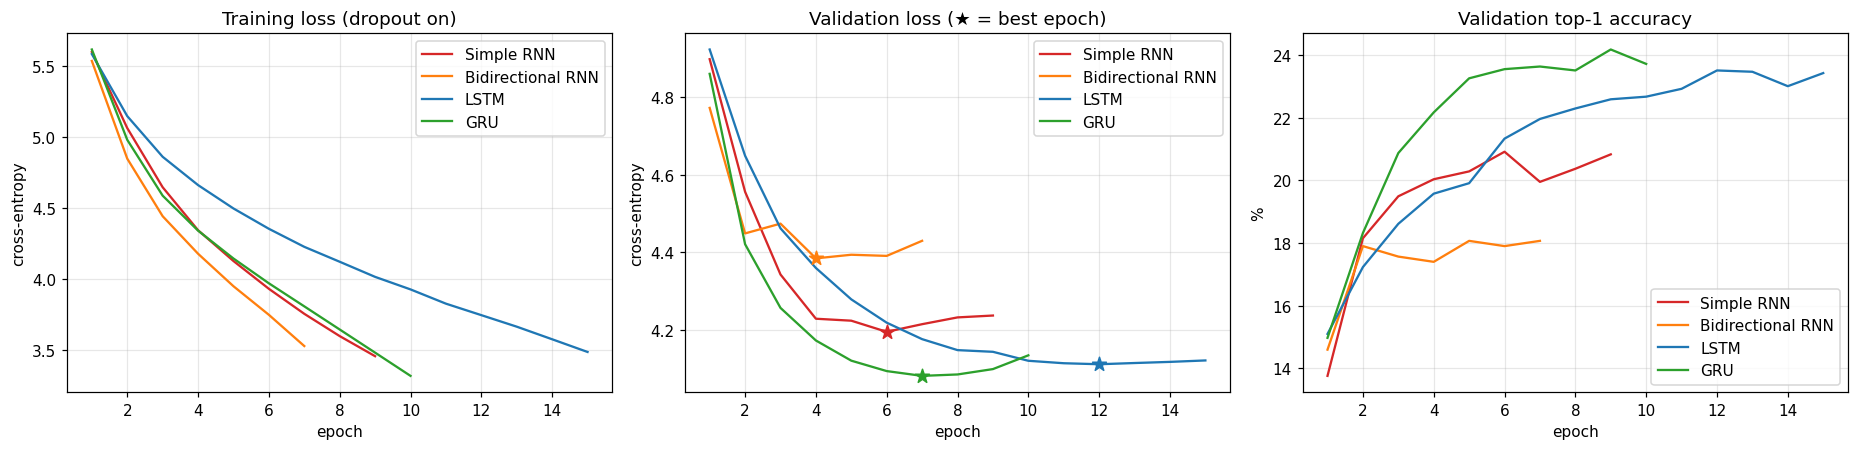

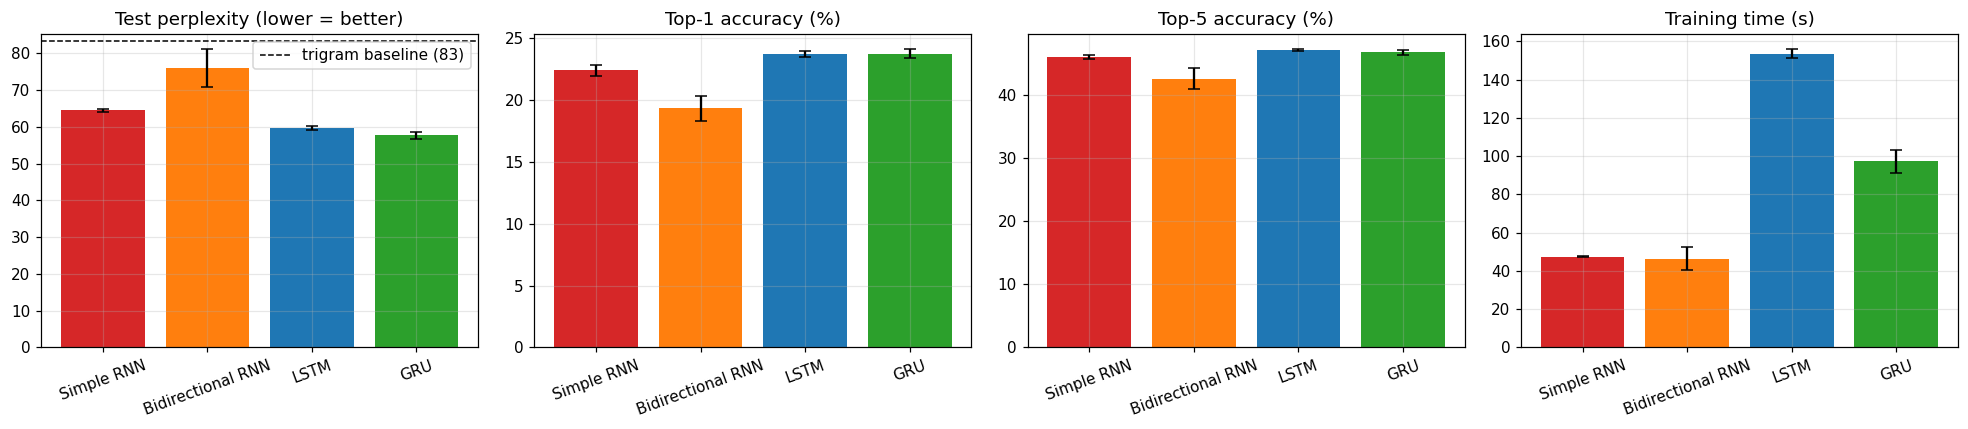

In [11]:
# ---------- training curves (seed = gen_seed) ----------
h = hist_df[hist_df.seed == CFG["gen_seed"]]
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
for k in KINDS:
    d = h[h.model == k]
    ax[0].plot(d.epoch, d.loss, color=COLORS[k], label=PRETTY[k])
    ax[1].plot(d.epoch, d.val_loss, color=COLORS[k], label=PRETTY[k])
    ax[1].scatter([d.loc[d.val_loss.idxmin(), "epoch"]], [d.val_loss.min()], color=COLORS[k], marker="*", s=90, zorder=5)
    ax[2].plot(d.epoch, 100 * d.val_acc, color=COLORS[k], label=PRETTY[k])
ax[0].set(title="Training loss (dropout on)", xlabel="epoch", ylabel="cross-entropy")
ax[1].set(title="Validation loss (★ = best epoch)", xlabel="epoch", ylabel="cross-entropy")
ax[2].set(title="Validation top-1 accuracy", xlabel="epoch", ylabel="%")
for a in ax: a.legend()
plt.tight_layout(); plt.savefig(RESULTS / "fig_training_curves.png", bbox_inches="tight"); plt.show()

# ---------- bar charts of test metrics ----------
fig, ax = plt.subplots(1, 4, figsize=(18, 4))
panels = [("test_ppl", "Test perplexity (lower = better)", 1), ("test_acc", "Top-1 accuracy (%)", 100),
          ("test_top5", "Top-5 accuracy (%)", 100), ("train_time_s", "Training time (s)", 1)]
for a, (col, title, sc) in zip(ax, panels):
    m = [sc * agg[(col, "mean")][k] for k in KINDS]; s = [sc * agg[(col, "std")][k] for k in KINDS]
    a.bar([PRETTY[k] for k in KINDS], m, yerr=s, color=[COLORS[k] for k in KINDS], capsize=4)
    if col == "test_ppl": a.axhline(tri_ppl, color="k", ls="--", lw=1, label=f"trigram baseline ({tri_ppl:.0f})"); a.legend()
    a.set_title(title); a.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.savefig(RESULTS / "fig_test_metrics.png", bbox_inches="tight"); plt.show()

## 7. Autoregressive text generation 


In [12]:
SEED_TEXTS = [
    "Human 1: Hi! How was your weekend?\nHuman 2: It was great, I went to a movie with my friends.\nHuman 1: That sounds",
    "Human 1: Do you like to travel?\nHuman 2: Yes, I love visiting new places.\nHuman 1: Where have you been",
    "Human 1: What do you do for work?\nHuman 2: I work at a school. What about you?\nHuman 1: I",
    "Human 1: I am so tired today.\nHuman 2: Why, what happened?\nHuman 1: I did not sleep",
    "Human 1: What is your favorite food?\nHuman 2: I really like to cook.\nHuman 1: Me too, do you",
]
seed_tok = [tokenize(s) for s in SEED_TEXTS]
for i, t in enumerate(seed_tok):
    oov = [w for w in t if w not in w2i]
    assert len(t) >= L, f"seed {i} shorter than the context window ({len(t)} < {L})"
    assert not oov, f"seed {i} contains out-of-vocabulary words {oov} - rewrite the seed with in-vocabulary words"
    print(f"seed {i}: {len(t)} tokens | all words in vocabulary")
seed_ids = [encode(t) for t in seed_tok]

seed 0: 25 tokens | all words in vocabulary
seed 1: 21 tokens | all words in vocabulary
seed 2: 21 tokens | all words in vocabulary
seed 3: 18 tokens | all words in vocabulary
seed 4: 20 tokens | all words in vocabulary


In [ ]:
def sample_next(logits, T, rng):
    z = logits.astype("float64") / T
    z[:, [PAD, UNK]] = -np.inf                        
    z -= z.max(axis=1, keepdims=True)
    p = np.exp(z); p /= p.sum(axis=1, keepdims=True)
    r = rng.random((len(p), 1))
    return np.minimum((p.cumsum(axis=1) < r).sum(axis=1), len(vocab) - 1)

def generate(model, seeds, n_per_seed, T, rng, steps):
    
    ctx = np.repeat(np.stack([s[-L:] for s in seeds]), n_per_seed, axis=0).astype("int32")
    out = []
    for _ in range(steps):
        logits = model(ctx, training=False).numpy()
        nxt = sample_next(logits, T, rng).astype("int32")
        out.append(nxt)
        ctx = np.concatenate([ctx[:, 1:], nxt[:, None]], axis=1)
    return np.stack(out, axis=1)

def detok(tokens):
    s = ""
    for t in tokens:
        if t in TAGS:        s += ("\n" if s else "") + ("Human 1:" if t == "<h1>" else "Human 2:")
        elif t in ".,!?":    s += t
        else:                s += " " + t
    return s
flat = lambda toks: detok(toks).replace("\n", "  ‖  ")

# ---------- generate for every model x temperature x seed ----------
GEN = {}    
for T in CFG["temperatures"]:
    for kind in KINDS:
        rng = np.random.default_rng(1000 + int(T * 100))        
        GEN[(kind, T)] = generate(gen_models[kind], seed_ids, CFG["n_samples_per_seed"], T, rng, CFG["gen_len"])
print("generated:", {k: v.shape for k, v in list(GEN.items())[:1]}, "x", len(GEN), "configurations")

generated: {('SimpleRNN', 0.3): (100, 40)} x 16 configurations


In [ ]:
# ---------- show samples ----------
def show(seed_idx, sample_idx=0):
    print("=" * 110); print(f"SEED {seed_idx}:  {flat(seed_tok[seed_idx])}"); print("=" * 110)
    for T in CFG["temperatures"]:
        print(f"\n--- temperature {T} ---")
        for kind in KINDS:
            g = GEN[(kind, T)][seed_idx * CFG["n_samples_per_seed"] + sample_idx]
            print(f"  {PRETTY[kind]:<18}: {flat(decode(g))}")
show(0); print(); show(1)

SEED 0:  Human 1: hi! how was your weekend?  ‖  Human 2: it was great, i went to a movie with my friends.  ‖  Human 1: that sounds

--- temperature 0.3 ---
  Simple RNN        :  good! what are you have to do you?  ‖  Human 2: i am like a lot of the world.  ‖  Human 1: hi!  ‖  Human 2: hi!  ‖  Human 2: hi!  ‖  Human 2: hi!  ‖  Human 2: hello!  ‖  Human 1: hi!  ‖  Human 2: hi
  Bidirectional RNN :  a lot of the most of the time.  ‖  Human 1: oh, that's a lot of the weekend. i am it.  ‖  Human 1: hi!  ‖  Human 2: hey, how are you?  ‖  Human 1: yes.  ‖  Human 2: thanks!  ‖  Human 2:
  LSTM              :  good! what are you?  ‖  Human 1: i am good. i am a bit of the year. i think it is a good.  ‖  Human 2: haha, i think i think that are you like to do you
  GRU               :  good! what are you?  ‖  Human 2: i am like a good. i am like a lot of the last time. i have to be a lot of the weekend.  ‖  Human 2: yeah, you are a lot

--- temperature 0.7 ---
  Simple RNN        :  good! i had t

In [15]:
train_bigrams  = set(zip(train_tok, train_tok[1:]))
train_4grams   = set(zip(train_tok, train_tok[1:], train_tok[2:], train_tok[3:]))
ngrams = lambda s, n: list(zip(*[s[i:] for i in range(n)]))
def distinct(s, n):
    g = ngrams(s, n); return len(set(g)) / len(g) if g else 1.0

def one_sample_metrics(seed_t, gen_t):
    full = seed_t + gen_t
    bg = ngrams(seed_t[-1:] + gen_t, 2)
    fg = ngrams(seed_t[-3:] + gen_t, 4)
    bc = collections.Counter(ngrams(gen_t, 2))
    run = max(len(list(g)) for _, g in __import__("itertools").groupby(gen_t))
    ids = list(map(int, encode(full)))
    start = len(seed_t)
    lp = [math.log(lm.prob(ids[i - 2], ids[i - 1], ids[i])) for i in range(start, len(ids))]
    pos = [i for i, t in enumerate(full) if t in TAGS]
    valid = all(full[a] != full[b] and b - a > 1 for a, b in zip(pos, pos[1:]))
    return dict(distinct1=distinct(gen_t, 1), distinct2=distinct(gen_t, 2), repetition=1 - distinct(gen_t, 3),
                loop=float(max(bc.values()) >= 3 or run >= 3), seen_bigram=np.mean([b in train_bigrams for b in bg]),
                ref_ppl=math.exp(-np.mean(lp)), valid_turns=float(valid), copied4=np.mean([g in train_4grams for g in fg]))

n_per = CFG["n_samples_per_seed"]
gm_rows = []
for (kind, T), G in GEN.items():
    per = []
    pooled_bg, pooled_uni = [], []
    for j in range(len(G)):
        s_t = seed_tok[j // n_per]; g_t = decode(G[j])
        per.append(one_sample_metrics(s_t, g_t)); pooled_bg += ngrams(g_t, 2); pooled_uni += g_t
    d = pd.DataFrame(per).mean()
    gm_rows.append(dict(model=kind, temperature=T, distinct1=d.distinct1, distinct2=d.distinct2,
                        distinct2_across=len(set(pooled_bg)) / len(pooled_bg), vocab_used=len(set(pooled_uni)),
                        repetition=d.repetition, loop_rate=100 * d.loop, seen_bigram=100 * d.seen_bigram,
                        ref_ppl=d.ref_ppl, valid_turns=100 * d.valid_turns, copied4=100 * d.copied4))
gen_df = pd.DataFrame(gm_rows)
gen_df.to_csv(RESULTS / "generation_metrics.csv", index=False)

names = {"distinct1": "distinct-1", "distinct2": "distinct-2", "distinct2_across": "distinct-2 (across)", "vocab_used": "unique words used",
         "repetition": "repetition rate", "loop_rate": "loop rate %", "seen_bigram": "seen-bigram %", "ref_ppl": "reference ppl",
         "valid_turns": "valid turn structure %", "copied4": "copied 4-gram %"}
for T in CFG["temperatures"]:
    t = gen_df[gen_df.temperature == T].set_index("model").reindex(KINDS).drop(columns="temperature").rename(columns=names)
    t.index = [PRETTY[k] for k in KINDS]
    print(f"\n=== Temperature {T} ==="); display(t.round(3))


=== Temperature 0.3 ===


,distinct-1,distinct-2,distinct-2 (across),unique words used,repetition rate,loop rate %,seen-bigram %,reference ppl,valid turn structure %,copied 4-gram %
Simple RNN,0.589,0.775,0.081,105,0.167,58.0,95.875,10.615,9.0,43.525
Bidirectional RNN,0.638,0.852,0.121,123,0.081,46.0,92.275,18.591,8.0,28.700
LSTM,0.613,0.826,0.103,126,0.090,61.0,96.750,12.217,10.0,34.100
GRU,0.622,0.840,0.105,137,0.075,47.0,96.025,14.417,25.0,31.750



=== Temperature 0.7 ===


,distinct-1,distinct-2,distinct-2 (across),unique words used,repetition rate,loop rate %,seen-bigram %,reference ppl,valid turn structure %,copied 4-gram %
Simple RNN,0.722,0.935,0.409,403,0.023,21.0,79.175,50.331,11.0,18.850
Bidirectional RNN,0.723,0.935,0.441,418,0.022,26.0,73.175,75.542,11.0,14.225
LSTM,0.723,0.950,0.421,408,0.012,21.0,80.650,51.288,15.0,16.825
GRU,0.736,0.944,0.404,413,0.020,21.0,82.275,44.181,14.0,20.800



=== Temperature 1.0 ===


,distinct-1,distinct-2,distinct-2 (across),unique words used,repetition rate,loop rate %,seen-bigram %,reference ppl,valid turn structure %,copied 4-gram %
Simple RNN,0.825,0.984,0.720,713,0.002,5.0,51.100,315.355,16.0,5.025
Bidirectional RNN,0.833,0.982,0.737,694,0.002,7.0,45.900,404.937,20.0,4.800
LSTM,0.833,0.984,0.691,652,0.002,4.0,56.075,246.035,18.0,5.800
GRU,0.831,0.986,0.699,663,0.001,3.0,56.750,243.654,26.0,6.500



=== Temperature 1.5 ===


,distinct-1,distinct-2,distinct-2 (across),unique words used,repetition rate,loop rate %,seen-bigram %,reference ppl,valid turn structure %,copied 4-gram %
Simple RNN,0.929,0.999,0.939,931,0.0,0.0,21.525,1901.503,50.0,0.400
Bidirectional RNN,0.928,0.999,0.947,945,0.0,0.0,19.025,2106.563,45.0,0.375
LSTM,0.912,0.996,0.912,889,0.0,0.0,27.825,1298.181,37.0,0.325
GRU,0.918,0.998,0.914,915,0.0,0.0,26.550,1400.838,44.0,0.675


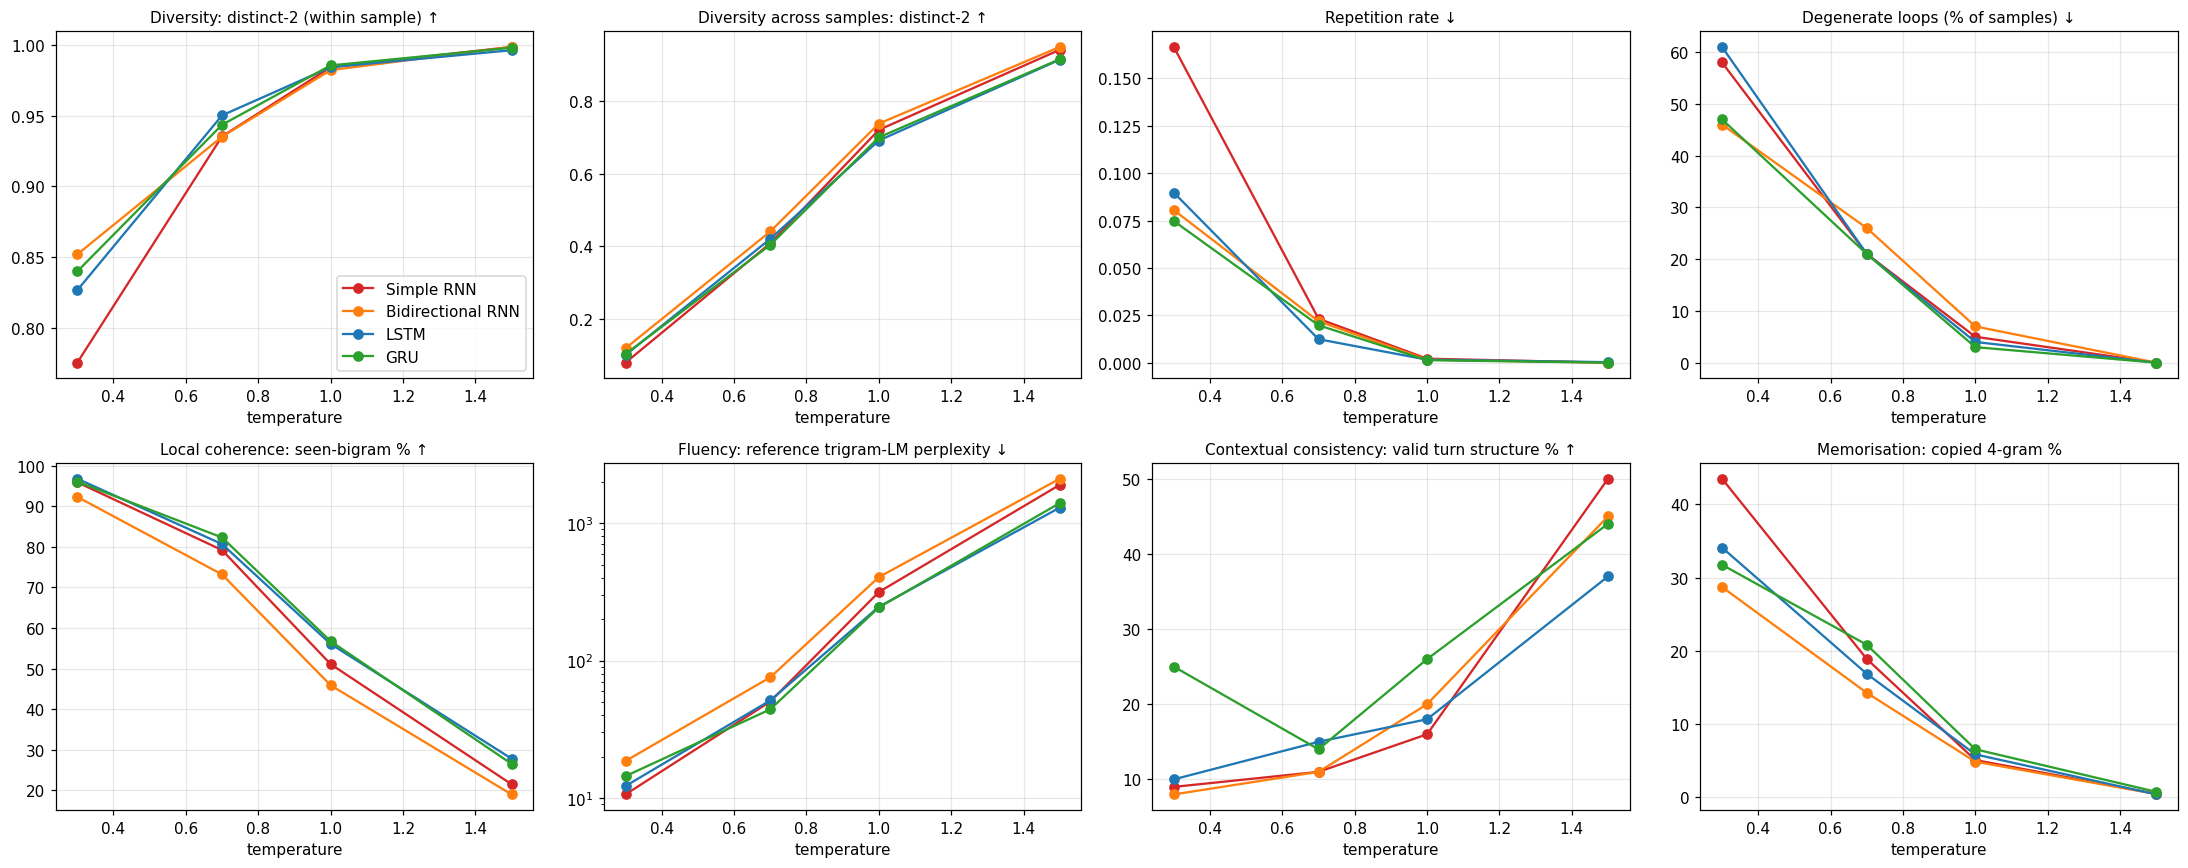

In [16]:
# ---------- temperature-effect plots ----------
panels = [("distinct2", "Diversity: distinct-2 (within sample) ↑"), ("distinct2_across", "Diversity across samples: distinct-2 ↑"),
          ("repetition", "Repetition rate ↓"), ("loop_rate", "Degenerate loops (% of samples) ↓"),
          ("seen_bigram", "Local coherence: seen-bigram % ↑"), ("ref_ppl", "Fluency: reference trigram-LM perplexity ↓"),
          ("valid_turns", "Contextual consistency: valid turn structure % ↑"), ("copied4", "Memorisation: copied 4-gram %")]
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for a, (col, title) in zip(axes.ravel(), panels):
    for k in KINDS:
        d = gen_df[gen_df.model == k].sort_values("temperature")
        a.plot(d.temperature, d[col], marker="o", color=COLORS[k], label=PRETTY[k])
    a.set_title(title, fontsize=10); a.set_xlabel("temperature")
    if col == "ref_ppl": a.set_yscale("log")
axes[0, 0].legend()
plt.tight_layout(); plt.savefig(RESULTS / "fig_temperature_effects.png", bbox_inches="tight"); plt.show()

In [17]:
# ---------- save ALL generated samples (every seed, model, temperature; first 3 samples each) to a readable file ----------
out = ["# Generated text samples", "",
       f"Models trained with seed {CFG['gen_seed']}; {CFG['gen_len']} tokens generated per sample; "
       f"temperatures {CFG['temperatures']}. `‖` marks a change of speaker turn.", ""]
for si, st in enumerate(seed_tok):
    out += [f"## Seed {si}", "", f"> **{flat(st)}**", ""]
    for T in CFG["temperatures"]:
        out += [f"### Temperature {T}", ""]
        for kind in KINDS:
            out.append(f"**{PRETTY[kind]}**")
            for j in range(min(3, n_per)):
                out.append(f"- {flat(decode(GEN[(kind, T)][si * n_per + j]))}")
            out.append("")
(RESULTS / "generated_samples.md").write_text("\n".join(out), encoding="utf-8")
print("saved results/generated_samples.md  ->", len(out), "lines")

saved results/generated_samples.md  -> 464 lines
